# Do the intermediate and coarse scales matter for the wavelet-moment potentials?

**Question.** The model imposes statistics of the wavelet coefficients of the signal at every scale, in two banks: Morlet with 1 wavelet per octave (Q=1) and Morlet with 3 per octave (Q=3, meant to capture rare events). Which scales of the Q=3 bank can be left out without making the model worse?

**Method.** For each scale we measure how much the corresponding term shapes the model distribution: half the variance, over signals, of its energy (defined below). A small value means the term carries little information. For the coarse scales we also check whether the two banks compensate each other.

**Result.** The Q=3 terms around scales 32 and 64 samples are negligible. At the coarse end (scales 128 and 256, and the low-pass channel) the Q=3 terms are large but almost cancel against the Q=1 terms of the same scale. The fine scales (up to about 16 samples) are not negligible.

## What is measured

- A *scale* is the period of the centre frequency of one wavelet filter, in samples. The *low-pass* channel is the filter that keeps only the slowest component of the signal.
- Each channel carries several *imposed moments* (statistics of its wavelet coefficient, in different magnitude ranges). Their Lagrange multipliers θ come from the regularised solve at the chosen regularisation, and φ are the statistics.
- *Energy of a channel*: E(x) = Σ θ·φ(x), summed over the moments of that channel. It is the channel's contribution to the log-probability of a signal x.
- *Half variance*: half the variance of E over signals. To first order it equals the information lost by removing the channel without refitting the others, and that is an upper bound on the information the channel really carries. Units: nats, for a whole signal. Dividing by d·ln 10 (d = 256 samples, so 589) gives the per-dimension value in digits used in the other tables.
- Computed on the 10 000 training signals and on the 10 000 signals generated by the model, for one seed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

res = pd.read_csv('results/var2d_per_channel.csv')
groups = pd.read_csv('results/var2d_bank_groups.csv')
BANKS = {'psi': 'Q=3 bank (Scalar_psi)', 'morlet': 'Q=1 bank (Scalar_morlet)'}


def mark_scale_axis(ax):
    ax.set_xscale('log'); ax.set_yscale('log'); ax.grid(alpha=0.3, which='both')
    ax.set_xlabel('scale = period of the wavelet [samples]', labelpad=18)
    ax.text(0.0, -0.13, '<- high frequency (fine scales)', transform=ax.transAxes, fontsize=8, ha='left', va='top')
    ax.text(1.0, -0.13, 'low frequency (coarse scales) ->', transform=ax.transAxes, fontsize=8, ha='right', va='top')


def mark_lowpass(ax, x, y, color):
    ax.plot([x], [y], 's', color=color, ms=9)
    ax.annotate('low-pass channel\n(slowest component,\nno scale)', (x, y), xytext=(0, -12),
                textcoords='offset points', ha='center', va='top', fontsize=8)

## 1. How much does each channel shape the model?

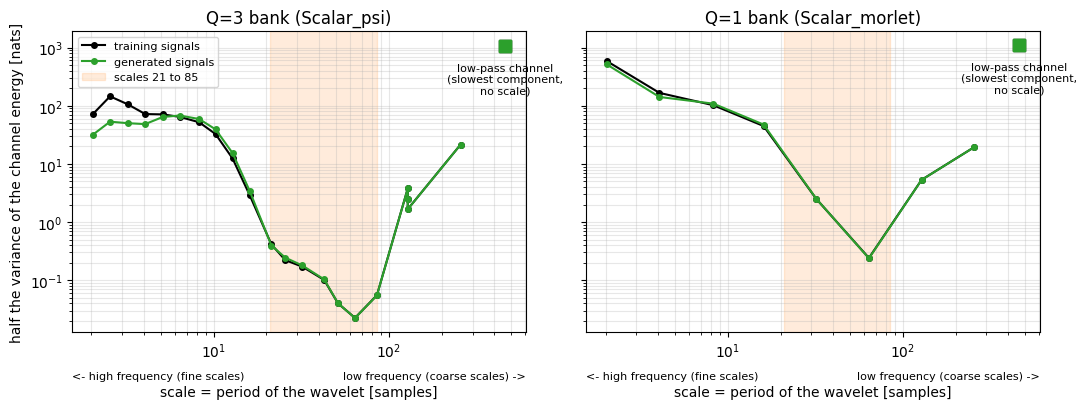

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (bank, title) in zip(axes, BANKS.items()):
    for src, col, lab in (('data', 'k', 'training signals'), ('model', 'tab:green', 'generated signals')):
        r = res[(res.potential == bank) & (res.source == src)].sort_values('period')
        fin = np.isfinite(r.period)
        ax.plot(r.period[fin], r.half_var_nats[fin], 'o-', color=col, ms=4, label=lab)
        xlp = r.period[fin].max() * 1.8
        ax.plot([xlp], r.half_var_nats[~fin], 's', color=col, ms=9)
    mark_lowpass(ax, xlp, float(r.half_var_nats[~fin].iloc[0]), 'tab:green')
    ax.axvspan(21, 85, color='tab:orange', alpha=0.15, label='scales 21 to 85')
    ax.set_title(title); mark_scale_axis(ax)
axes[0].set_ylabel('half the variance of the channel energy [nats]'); axes[0].legend(fontsize=8)
fig.tight_layout()

Both banks have a minimum around 64 samples and rise towards the largest scales and the low-pass. Training and generated signals agree from 6 samples upwards. Below that, in the Q=3 bank, the model's energy varies about half as much as the training data's.

In [3]:
def table_per_channel(bank):
    d = res[(res.potential == bank) & (res.source == 'data')].sort_values('period').reset_index(drop=True)
    m = res[(res.potential == bank) & (res.source == 'model')].sort_values('period').reset_index(drop=True)
    out = pd.DataFrame({'scale [samples]': d.period.map(lambda p: 'low-pass' if np.isinf(p) else f'{p:.1f}'),
                        'imposed moments': d.n_stats,
                        'half variance, training signals [nats]': d.half_var_nats,
                        'half variance, generated signals [nats]': m.half_var_nats})
    fmt = {c: '{:.3g}' for c in out.columns[2:]}
    return out.style.hide(axis='index').format(fmt)

**Table 1. Q=3 bank.** One row per channel (one wavelet filter): its scale, how many moments it imposes, half the variance of its energy over the training and the generated signals. Channels of equal scale (three filters at 128 samples) are listed separately.

In [4]:
table_per_channel('psi')

scale [samples],imposed moments,"half variance, training signals [nats]","half variance, generated signals [nats]"
2.0,3,72.3,32
2.6,3,145,53.2
3.2,3,105,50.1
4.1,5,71.9,48.3
5.1,7,70.9,64.1
6.4,7,64.3,67.9
8.3,7,51.9,59
10.2,7,32.6,39.2
12.8,7,12.4,15.4
16.0,7,2.95,3.48


**Table 2. Q=1 bank.** Same columns.

In [5]:
table_per_channel('morlet')

scale [samples],imposed moments,"half variance, training signals [nats]","half variance, generated signals [nats]"
2.0,5,585,513
4.1,7,166,141
8.3,7,102,109
16.0,7,44.8,47.4
32.0,7,2.51,2.52
64.0,7,0.241,0.238
128.0,7,5.32,5.31
256.0,7,19.4,19.4
low-pass,6,1.11e+03,1.1e+03


## 2. Do the two banks compensate each other?

Each Q=3 channel is assigned to the Q=1 channel with the most similar filter. The three Q=3 filters of an octave together cover the Q=1 filter of that octave, so each *group* is one Q=1 channel and the Q=3 channels assigned to it. The energy of the Q=3 side is the sum of the energies of its channels. If the two sides have large energies of opposite sign, each has a large variance but the *sum* of the two energies is small: the model needs only one of them.

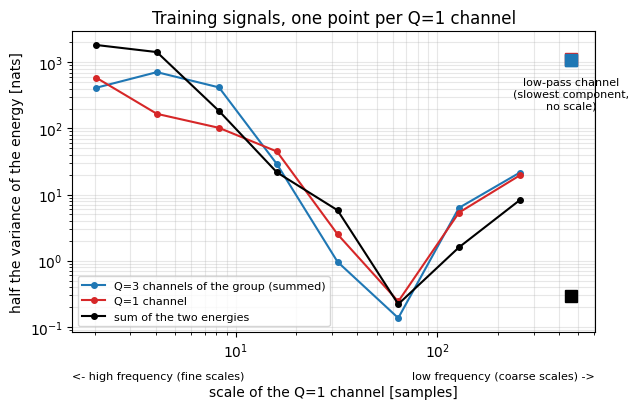

In [6]:
g = groups[~groups.group.str.startswith('scales')]
gd = g[g.source == 'data'].sort_values('period_morlet').reset_index(drop=True)
gm = g[g.source == 'model'].sort_values('period_morlet').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
fin = np.isfinite(gd.period_morlet)
xlp = gd.period_morlet[fin].max() * 1.8
for col_name, col, lab in (('half_var_psi', 'tab:blue', 'Q=3 channels of the group (summed)'),
                           ('half_var_morlet', 'tab:red', 'Q=1 channel'),
                           ('half_var_sum', 'k', 'sum of the two energies')):
    ax.plot(gd.period_morlet[fin], gd[col_name][fin], 'o-', color=col, ms=4, label=lab)
    ax.plot([xlp], gd[col_name][~fin], 's', color=col, ms=9)
mark_lowpass(ax, xlp, float(gd.half_var_psi[~fin].iloc[0]), 'tab:blue')
mark_scale_axis(ax); ax.set_ylabel('half the variance of the energy [nats]')
ax.set_xlabel('scale of the Q=1 channel [samples]', labelpad=18)
ax.set_title('Training signals, one point per Q=1 channel'); ax.legend(fontsize=8)
fig.tight_layout()

**Table 3.** One row per group. The last row takes the groups at 128 and 256 samples together, without the low-pass.

In [7]:
per3 = res[(res.potential == 'psi') & (res.source == 'data')].set_index('channel').period
scale_txt = lambda x: 'low-pass' if np.isinf(x) else f'{x:.3g}'
tab3 = pd.DataFrame({
    'Q=1 channel, scale [samples]': gd.period_morlet.map(lambda x: 'low-pass' if np.isinf(x) else ('' if np.isnan(x) else f'{x:.3g}')),
    'Q=3 channels of the group, scales [samples]': gd.psi_channels.map(lambda t: ', '.join(scale_txt(per3[int(c)]) for c in str(t).split())),
    'half variance, Q=3 channels summed [nats]': gd.half_var_psi,
    'half variance, Q=1 channel [nats]': gd.half_var_morlet,
    'correlation of the two energies': gd['corr'],
    'half variance of the sum, training signals [nats]': gd.half_var_sum,
    'half variance of the sum, generated signals [nats]': gm.half_var_sum})
last = groups[groups.group.str.startswith('scales')].set_index('source')
tab3.loc[len(tab3)] = ['128 and 256 together', ', '.join(scale_txt(per3[int(c)]) for c in last.loc['data', 'psi_channels'].split()),
                       last.loc['data', 'half_var_psi'], last.loc['data', 'half_var_morlet'], last.loc['data', 'corr'],
                       last.loc['data', 'half_var_sum'], last.loc['model', 'half_var_sum']]
tab3.style.hide(axis='index').format({c: '{:.3g}' for c in tab3.columns[2:]})

"Q=1 channel, scale [samples]","Q=3 channels of the group, scales [samples]","half variance, Q=3 channels summed [nats]","half variance, Q=1 channel [nats]",correlation of the two energies,"half variance of the sum, training signals [nats]","half variance of the sum, generated signals [nats]"
2.03,"2.05, 2.56",412,585,0.847,1.83e+03,1.14e+03
4.06,"3.24, 4.06, 5.12",710,166,0.803,1.43e+03,977
8.26,"6.4, 8.26, 10.2",418,102,-0.813,184,189
16,"12.8, 16, 21.3",28.9,44.8,-0.723,21.7,23.8
32,"25.6, 32, 42.7",0.958,2.51,0.748,5.78,6.06
64,"51.2, 64, 85.3",0.135,0.241,-0.435,0.22,0.214
128,"128, 128, 128",6.29,5.32,-0.866,1.59,1.57
256,256,21.4,19.4,-0.8,8.2,8.21
low-pass,low-pass,1.08e+03,1.11e+03,-1,0.288,0.283
128 and 256 together,"128, 128, 128, 256",28.3,22,-0.932,3.81,3.87


## Reading

- **Groups at 32 and 64 samples:** the Q=3 side has a half variance of about 1 and 0.1 nats, negligible without needing any compensation.
- **Low-pass:** both banks have a half variance of about 1100 nats, the sum is 0.3 nats. The energies cancel (correlation close to −1): one bank is enough.
- **128 and 256 samples:** each bank has 20 to 30 nats, the sum is 3.8 nats for the two scales together (1.6 at 128, 8.2 at 256). Most of the variance compensates, a few nats remain.
- **8 and 16 samples:** partial cancellation (correlation about −0.7 to −0.8), but 184 and 22 nats remain in the sum.
- **2 and 4 samples:** the two energies are positively correlated and the sum is larger than each: no compensation.

## Limits

- First order only: half the variance underestimates the information of a term whose energy is dominated by rare events. At the fine scales, where rare events live, these values are a lower estimate.
- One seed and one regularisation value. The assignment of Q=3 channels to Q=1 channels follows the filter overlap (0.58 to 1), so it is approximate at the boundaries between octaves.
- A small value for the sum shows that removing the Q=3 channels and refitting the Q=1 channel can recover the constraint. It is not a proof: the information is measured only by refitting the model without these channels, which was not done.